In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import OneHotEncoder
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, make_scorer
import sqlite3
import warnings
warnings.filterwarnings('ignore')

In [3]:

# Establish connection to the existing database file
conn = sqlite3.connect("Sales_data.db")
cursor=conn.cursor()
# Read the SQL table directly back into a Pandas DataFrame
df = pd.read_sql_query("SELECT * FROM Sales_Data", conn)
conn.close()

In [7]:
# cursor.execute(
#     """
#     SELECT Sales 
#     FROM Sales_Data
#     WHERE Store = ?
#       AND DATE(Sales_date) < ?
#       AND DATE(Sales_date) >= ?
#     ORDER BY Sales_date DESC;
#     """,
#     ("1",'2015-07-24','2015-06-24')
# )

# sales = cursor.fetchall()

In [4]:
#df=pd.read_parquet('final_data.parquet')
df.head()

,Sales_date,Store,DayOfWeek,Sales,Customers,Promo,SchoolHoliday,month,day,StoreType,...,7_8_lag_dif,Is_Promo2_Active,consecutive_promo2_days,last_month_same_week_avg,promo_x_dayofweek,promo_x_storetype,promo2_x_dayofweek,promo2_x_storetype,days_till_next_holiday,days_after_holiday
0,2014-05-17 00:00:00,415,6,5652,506,0,0,5,17,d,...,21.0,0,0,8836.994495,0_6,0_d,0_6,0_d,13.0,15.0
1,2014-11-19 00:00:00,951,3,6024,651,0,0,11,19,d,...,-1477.0,0,688,6320.294504,0_3,0_d,0_3,0_d,33.0,12.0
2,2015-01-14 00:00:00,126,3,5045,465,1,0,1,14,d,...,-425.0,0,744,6835.335407,1_3,1_d,0_3,0_d,19.0,5.0
3,2015-01-15 00:00:00,11,4,6771,900,1,0,1,15,a,...,-2410.0,1,745,10604.964875,1_4,1_a,1_4,1_a,18.0,6.0
4,2015-02-06 00:00:00,601,5,5872,438,1,0,2,6,d,...,1359.0,0,767,7676.820494,1_5,1_d,0_5,0_d,0.0,0.0


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 844338 entries, 0 to 844337
Data columns (total 35 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   Sales_date                844338 non-null  str    
 1   Store                     844338 non-null  str    
 2   DayOfWeek                 844338 non-null  str    
 3   Sales                     844338 non-null  int64  
 4   Customers                 844338 non-null  int64  
 5   Promo                     844338 non-null  int64  
 6   SchoolHoliday             844338 non-null  int64  
 7   month                     844338 non-null  int64  
 8   day                       844338 non-null  int64  
 9   StoreType                 844338 non-null  str    
 10  Assortment                844338 non-null  str    
 11  CompetitionDistance       844338 non-null  float64
 12  Promo2                    844338 non-null  int64  
 13  consecutive_promo_days    844338 non-null  int64  
 14 

In [10]:
df.dtypes

Sales_date                      str
Store                           str
DayOfWeek                       str
Sales                         int64
Customers                     int64
Promo                         int64
SchoolHoliday                 int64
month                         int64
day                           int64
StoreType                       str
Assortment                      str
CompetitionDistance         float64
Promo2                        int64
consecutive_promo_days        int64
days_since_last_refurb      float64
7th_lag                     float64
14th_lag                    float64
21st_lag                    float64
28th_lag                    float64
avg_last_3_weeks            float64
ma_3d_lag7                  float64
std_3d_lag7                 float64
ma_7d_lag7                  float64
ma_15d_lag7                 float64
ma_30d_lag7                 float64
7_8_lag_dif                 float64
Is_Promo2_Active              int64
consecutive_promo2_days     

In [11]:
df.select_dtypes('int64').columns

Index(['Sales', 'Customers', 'Promo', 'SchoolHoliday', 'month', 'day',
       'Promo2', 'consecutive_promo_days', 'Is_Promo2_Active',
       'consecutive_promo2_days'],
      dtype='str')

In [12]:
type(df.reset_index(drop=True).iloc[0])

pandas.Series

In [13]:
df.select_dtypes('category').columns


Index([], dtype='str')

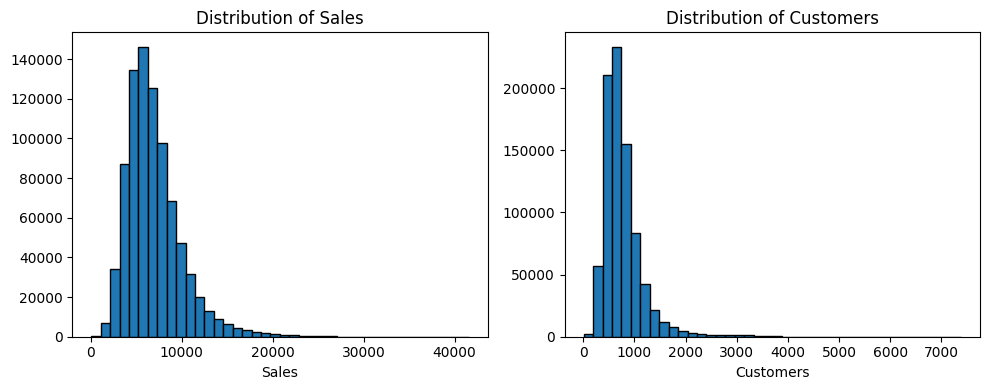

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(df['Sales'], bins=40,edgecolor='black')
axes[0].set_title('Distribution of Sales')
axes[0].set_xlabel('Sales')
axes[1].hist(df['Customers'], bins=40,edgecolor='black')
axes[1].set_title('Distribution of Customers')
axes[1].set_xlabel('Customers')
plt.tight_layout()
plt.show()

In [15]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 844338 entries, 0 to 844337
Data columns (total 35 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   Sales_date                844338 non-null  str    
 1   Store                     844338 non-null  str    
 2   DayOfWeek                 844338 non-null  str    
 3   Sales                     844338 non-null  int64  
 4   Customers                 844338 non-null  int64  
 5   Promo                     844338 non-null  int64  
 6   SchoolHoliday             844338 non-null  int64  
 7   month                     844338 non-null  int64  
 8   day                       844338 non-null  int64  
 9   StoreType                 844338 non-null  str    
 10  Assortment                844338 non-null  str    
 11  CompetitionDistance       844338 non-null  float64
 12  Promo2                    844338 non-null  int64  
 13  consecutive_promo_days    844338 non-null  int64  
 14 

In [16]:
df.dtypes

Sales_date                      str
Store                           str
DayOfWeek                       str
Sales                         int64
Customers                     int64
Promo                         int64
SchoolHoliday                 int64
month                         int64
day                           int64
StoreType                       str
Assortment                      str
CompetitionDistance         float64
Promo2                        int64
consecutive_promo_days        int64
days_since_last_refurb      float64
7th_lag                     float64
14th_lag                    float64
21st_lag                    float64
28th_lag                    float64
avg_last_3_weeks            float64
ma_3d_lag7                  float64
std_3d_lag7                 float64
ma_7d_lag7                  float64
ma_15d_lag7                 float64
ma_30d_lag7                 float64
7_8_lag_dif                 float64
Is_Promo2_Active              int64
consecutive_promo2_days     

In [17]:
# class DataPreprocessor:
#     def __init__(self):
#         """
#         Initializes the DataPreprocessor with a OneHotEncoder and defines
#         the features to be transformed and dropped.
#         """
#         # Initialize OneHotEncoder with handle_unknown='ignore' and sparse_output=False
#         # as was used in the notebook (cell ANMlX2vAI9UJ)
#         self.ohe_categorical = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

#         # Define categorical features for One-Hot Encoding as seen in the notebook (cell ANMlX2vAI9UJ)
#         self.categorical_features_for_ohe = ['DayOfWeek','month', 'year','day', 'StoreType', 'Assortment']

#         # Define original categorical features to drop after they have been transformed.
#         # This list mirrors the 'categorical_features_to_drop' in the notebook (cell 2YoO2OFzNDCp).
#         # Note: 'day' is included in `categorical_features_for_ohe` but not in this `features_to_drop_after_ohe`
#         # list, consistent with the notebook's behavior where both original 'day' and
#         # one-hot encoded 'day_X' columns were present in the final DataFrame.
#         self.features_to_drop_after_ohe = ['DayOfWeek','month', 'year','day', 'StoreType',  'Assortment']

#     def fit(self, df):
#         """
#         Fits the OneHotEncoder and determines the full set of PromoInterval columns
#         from the provided training DataFrame.

#         Args:
#             df (pd.DataFrame): The training DataFrame used to fit the transformers.

#         Returns:
#             self: The fitted DataPreprocessor instance.

#         Raises:
#             ValueError: If required columns for fitting are missing from the DataFrame.
#         """
#         # Basic data validation for required columns during fitting
#         required_for_fit = list(set(self.categorical_features_for_ohe ))
#         if not all(col in df.columns for col in required_for_fit):
#             missing_cols = [col for col in required_for_fit if col not in df.columns]
#             raise ValueError(f"Missing one or more required columns for fitting: {missing_cols}")

#         # Fit the OneHotEncoder on the specified categorical features
#         self.ohe_categorical.fit(df[self.categorical_features_for_ohe])

#         return self

#     def transform(self, df_input):
#         """
#         Performs data validation, feature transformation, and one-hot encoding
#         on the input DataFrame or Series based on the fitted preprocessor.

#         Args:
#             df_input (pd.DataFrame or pd.Series): The DataFrame or Series to transform.

#         Returns:
#             pd.DataFrame: The transformed DataFrame with new features and dropped original columns.

#         Raises:
#             ValueError: If the preprocessor has not been fitted or if required columns
#                         for transformation are missing from the input.
#         """

#         # Ensure input is a DataFrame; if it's a Series, convert it to a single-row DataFrame.
#         if isinstance(df_input, pd.Series):
#             # Ensure the Series has a name, otherwise, to_frame().T might behave unexpectedly
#             if df_input.name is None:
#                 df_input.name = 'temp_row'
#             df_transformed = df_input.to_frame().T
#         else:
#             df_transformed = df_input.copy()

#         # Basic data validation for required columns during transformation
#         required_for_transform = list(set(self.categorical_features_for_ohe))
#         if not all(col in df_transformed.columns for col in required_for_transform):
#             missing_cols = [col for col in required_for_transform if col not in df_transformed.columns]
#             raise ValueError(f"Input DataFrame/Series is missing required columns for transformation: {missing_cols}")

#         # 2. One-Hot Encoding for other categorical features (as seen in cell ANMlX2vAI9UJ)
#         encoded_data_array = self.ohe_categorical.transform(df_transformed[self.categorical_features_for_ohe])
#         encoded_data_df = pd.DataFrame(encoded_data_array, columns=self.ohe_categorical.get_feature_names_out(self.categorical_features_for_ohe), index=df_transformed.index)

#         # Reset index of df_transformed and the encoded DataFrames to ensure clean concatenation
#         # (as seen in cell 2YoO2OFzNDCp using .reset_index(drop=True))
#         df_transformed_reset = df_transformed.reset_index(drop=True)
#         encoded_data_df_reset = encoded_data_df.reset_index(drop=True)

#         # Concatenate all transformed features (as seen in cell 2YoO2OFzNDCp)
#         df_final = pd.concat([df_transformed_reset, encoded_data_df_reset], axis=1)

#         # Drop original categorical features and PromoInterval (as seen in cell 2YoO2OFzNDCp)
#         # Ensure that only columns actually present in df_final are dropped.
#         cols_to_drop_present = [col for col in self.features_to_drop_after_ohe if col in df_final.columns]
#         df_final = df_final.drop(columns=cols_to_drop_present)

#         # If the input was a Series, the output should also ideally be a Series if it represents a single row.
#         # However, since the transformation adds many columns, returning a DataFrame is more appropriate
#         # and consistent with the notebook's output (df_final is always a DataFrame).
#         return df_final

#     def fit_transform(self, df):
#         """
#         Fits the preprocessor to the DataFrame and then transforms it in one step.
#         Convenience method equivalent to calling .fit(df).transform(df).

#         Args:
#             df (pd.DataFrame): The DataFrame to fit and transform.

#         Returns:
#             pd.DataFrame: The transformed DataFrame.
#         """
#         return self.fit(df).transform(df)

In [18]:
df.drop(columns=['Promo2','last_month_same_week_avg'],inplace=True)


In [19]:
df.columns

Index(['Sales_date', 'Store', 'DayOfWeek', 'Sales', 'Customers', 'Promo',
       'SchoolHoliday', 'month', 'day', 'StoreType', 'Assortment',
       'CompetitionDistance', 'consecutive_promo_days',
       'days_since_last_refurb', '7th_lag', '14th_lag', '21st_lag', '28th_lag',
       'avg_last_3_weeks', 'ma_3d_lag7', 'std_3d_lag7', 'ma_7d_lag7',
       'ma_15d_lag7', 'ma_30d_lag7', '7_8_lag_dif', 'Is_Promo2_Active',
       'consecutive_promo2_days', 'promo_x_dayofweek', 'promo_x_storetype',
       'promo2_x_dayofweek', 'promo2_x_storetype', 'days_till_next_holiday',
       'days_after_holiday'],
      dtype='str')

In [20]:
all_features=['Date', 'Store', 'DayOfWeek', 'Sales', 'Customers', 'Open', 'Promo',
       'SchoolHoliday', 'year', 'month', 'day', 'StoreType', 'Assortment',
       'CompetitionDistance', 'Promo2', 'quarter', 'consecutive_promo_days',
       'days_since_last_refurb', 'days_until_next_refurb', '7th_lag',
       '14th_lag', '21st_lag', '28th_lag', 'avg_last_3_weeks', 'ma_3d_lag7',
       'std_3d_lag7', 'ma_7d_lag7', 'ma_15d_lag7', 'ma_30d_lag7',
       'ema_15d_lag7', 'ema_30d_lag7', '7_8_lag_dif', 'Is_Promo2_Active',
       'consecutive_promo2_days', 'week_of_month', 'last_month_same_week_avg',
       'promo_x_dayofweek', 'promo_x_storetype', 'promo2_x_dayofweek',
       'promo2_x_storetype', 'days_till_next_holiday', 'days_after_holiday']

In [21]:
df=df[df['Sales'] >0]

In [22]:
categorical_feature=['Assortment','StoreType','DayOfWeek','month','Store','promo_x_dayofweek','promo_x_storetype','promo2_x_dayofweek','promo2_x_storetype']
df[categorical_feature] = df[categorical_feature].astype('category')

In [23]:
# selected_features=['Sales', 'Customers','Date','Store', 'DayOfWeek', 'Promo', 'SchoolHoliday','CompetitionDistance', 'month', 'day', 'StoreType', 'Assortment', 'Promo2', 'consecutive_promo_days', 'days_since_last_refurb', '7th_lag', '14th_lag', '21st_lag', '28th_lag', 'avg_last_3_weeks', 'ma_3d_lag7', 'std_3d_lag7', 'ma_7d_lag7', 'ma_15d_lag7', 'ma_30d_lag7',  '7_8_lag_dif', 'Is_Promo2_Active', 'consecutive_promo2_days', 'last_month_same_week_avg', 'promo_x_dayofweek', 'promo_x_storetype', 'promo2_x_dayofweek', 'promo2_x_storetype', 'days_till_next_holiday', 'days_after_holiday']
# df=df[selected_features]


In [24]:

# df=encode_cyclical_feature(df, 'DayOfWeek', 6)
# df=encode_cyclical_feature(df, 'month', 12)
split_date= '2014-12-31'
data_train = df[df['Sales_date'] <= split_date]
data_train.drop(columns=['Sales_date'],inplace=True)
data_test = df[df['Sales_date'] > split_date]
data_test.drop(columns=['Sales_date'],inplace=True)

In [25]:
# import pandas as pd
# from sklearn.feature_selection import mutual_info_regression

# # 1. Prepare base data
# clean_data = df.dropna(axis=0)

# # Drop target and unneeded/string non-feature columns
# columns_to_drop = ['Sales', 'Customers', 'Date']  # Add any other non-numeric string cols
# X = clean_data.drop(columns=[c for c in columns_to_drop if c in clean_data.columns])
# y = clean_data['Sales']

# # 2. Encode categorical/object columns & build discrete feature mask
# X_encoded = X.copy()
# discrete_mask = []

# for col in X_encoded.columns:
#     # Convert string/category columns to integer codes
#     if X_encoded[col].dtype.name in ['category', 'object']:
#         X_encoded[col] = X_encoded[col].astype('category').cat.codes
#         discrete_mask.append(True)
#     # Mark integer columns (Store, DayOfWeek, etc.) as discrete
#     elif pd.api.types.is_integer_dtype(X_encoded[col]):
#         discrete_mask.append(True)
#     else:
#         discrete_mask.append(False)

# # 3. Calculate mutual information
# mi_scores = mutual_info_regression(
#     X_encoded, 
#     y, 
#     discrete_features=discrete_mask, 
#     random_state=42
# )

# # 4. Format results with real feature names
# mi_df = pd.DataFrame({"MI Score": mi_scores}, index=X_encoded.columns)
# print(mi_df.sort_values(by="MI Score", ascending=False))

In [26]:
# preprocessor = DataPreprocessor()
# x_train=preprocessor.fit_transform(data_train).drop(columns=['Sales','Customers'])
x_train=data_train.drop(columns=['Sales','Customers'])
y_train_sales=data_train['Sales']
y_train_customers=data_train['Customers']
#y_train_ratio=data_train['Sale_Customer_ratio']

x_test=data_test.drop(columns=['Sales','Customers'])
y_test_sales=data_test['Sales']
y_test_customers=data_test['Customers']
#y_test_ratio=data_test['Sale_Customer_ratio']

#x_train_customers=preprocessor.fit_transform(data_train).drop(columns=['Sales','Customers'])
#x_test_customers=preprocessor.transform(data_test).drop(columns=['Sales','Customers'])

In [27]:
print(type(x_train))

<class 'pandas.DataFrame'>


In [28]:
import numpy as np

def rmspe(y_true, y_pred):
    # Filter out zero sales / closed store days
    mask = y_true > 0
    y_true = y_true[mask]
    y_pred = y_pred[mask]

    # Calculate percentage error
    percentage_error = (y_true - y_pred) / y_true

    # Calculate RMSPE
    rmspe = np.sqrt(np.mean(np.square(percentage_error)))
    return rmspe

XGBoost Customer Prediction RMSE: 88.55
XGBoost Customer Prediction MAE: 58.05
XGBoost Customer Prediction R² Score: 0.9479
XGBoost Customer Prediction RMSPE: 0.1318
 
Correlation between Predicted Customers and Actual Sales: 0.7845
Correlation between Predicted Customers and Actual Customers: 0.9741
Correlation between Actual Customers and Actual Sales: 0.8072


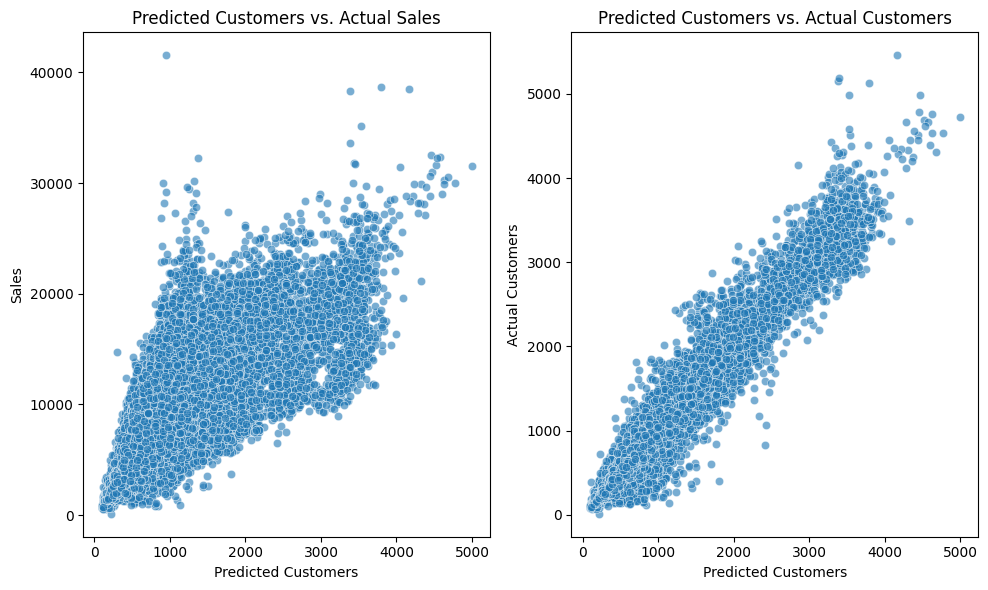

In [29]:
xgb_customer_model = XGBRegressor(
    max_depth=8,
    n_estimators=500,
    learning_rate=0.1,
    enable_categorical=True,
    device='gpu', # Use GPU if available
    random_state=42, # for reproducibility
)

# Train the model on the log-transformed target variable for customers
xgb_customer_model.fit(
    x_train, np.log1p(y_train_customers))

# Make predictions on the test set and inverse transform them
y_pred_customers_log = xgb_customer_model.predict(x_test)
y_pred_customers = np.expm1(y_pred_customers_log)

# Evaluate the model
rmse_customers = np.sqrt(mean_squared_error(y_test_customers, y_pred_customers))
mae_customers = mean_absolute_error(y_test_customers, y_pred_customers)
r2_customers = r2_score(y_test_customers, y_pred_customers)
rmspe_customers = rmspe(y_test_customers, y_pred_customers)

print(f'XGBoost Customer Prediction RMSE: {rmse_customers:.2f}')
print(f'XGBoost Customer Prediction MAE: {mae_customers:.2f}')
print(f'XGBoost Customer Prediction R² Score: {r2_customers:.4f}')
print(f'XGBoost Customer Prediction RMSPE: {rmspe_customers:.4f}')

print(' ')

if isinstance(y_pred_customers, np.ndarray):
    y_pred_customers_series = pd.Series(y_pred_customers, index=y_test_sales.index)
else:
    y_pred_customers_series = y_pred_customers

correlation_pred_customers_sales = y_pred_customers_series.corr(y_test_sales)
print(f"Correlation between Predicted Customers and Actual Sales: {correlation_pred_customers_sales:.4f}")

correlation_pred_customers_customer = y_pred_customers_series.corr(y_test_customers)
print(f"Correlation between Predicted Customers and Actual Customers: {correlation_pred_customers_customer:.4f}")

# Calculate the correlation between actual customers and actual sales
correlation_actual_customers_sales = y_test_customers.corr(y_test_sales)
print(f"Correlation between Actual Customers and Actual Sales: {correlation_actual_customers_sales:.4f}")


# Plotting residuals
fig, axes = plt.subplots(1,2,figsize=(10, 6))

sns.scatterplot(x=y_pred_customers_series, y=y_test_sales, alpha=0.6,ax=axes[0])
axes[0].set_title('Predicted Customers vs. Actual Sales')
axes[0].set_xlabel('Predicted Customers')
axes[0].set_ylabel('Sales')

sns.scatterplot(x=y_pred_customers_series, y=y_test_customers, alpha=0.6,ax=axes[1])
axes[1].set_title('Predicted Customers vs. Actual Customers')
axes[1].set_xlabel('Predicted Customers')
axes[1].set_ylabel('Actual Customers')

plt.tight_layout()
plt.show()


In [40]:
categorical_schemas = {col: x_train[col].dtype for col in x_train.select_dtypes(include='category').columns}

In [58]:
type(categorical_schemas)

dict

In [ ]:
import pickle


# 1. Export (Dump) to a binary file (use 'wb')
with open("categorical_schemas.pkl", "wb") as file:
    pickle.dump(categorical_schemas, file)

# 2. Load from a binary file (use 'rb')
with open("data.pkl", "rb") as file:
    loaded_dict = pickle.load(file)

print(loaded_dict)


In [53]:
single_test = pd.DataFrame(x_test.iloc[0:1], columns=x_test.columns)

In [54]:
for col, dtype in categorical_schemas.items():
    single_test[col] = single_test[col].astype(dtype)

In [55]:
single_test

,Store,DayOfWeek,Promo,SchoolHoliday,month,day,StoreType,Assortment,CompetitionDistance,consecutive_promo_days,...,ma_30d_lag7,7_8_lag_dif,Is_Promo2_Active,consecutive_promo2_days,promo_x_dayofweek,promo_x_storetype,promo2_x_dayofweek,promo2_x_storetype,days_till_next_holiday,days_after_holiday
2,126,3,1,0,1,14,d,Basic,3370.0,3,...,4854.1,-425.0,0,744,1_3,1_d,0_3,0_d,19.0,5.0


In [57]:
y_pred_single= xgb_customer_model.predict(single_test)
y_pred_single

array([6.3175497], dtype=float32)

In [30]:

# 1. Generate customer predictions for the *training* set (using the already trained xgb_customer_model)
# The xgb_customer_model was trained in q96MxYhjTaPV: xgb_customer_model.fit(x_train, np.log1p(y_train_customers))
# Now we use it to predict customers on the x_train data itself.
y_pred_customers_train_log = xgb_customer_model.predict(x_train)
y_pred_customers_train = pd.Series(np.expm1(y_pred_customers_train_log), index=x_train.index)

# 2. Augment x_train with these predictions for sales model training
x_train_augmented_sales = x_train.copy()
x_train_augmented_sales.columns = x_train_augmented_sales.columns.astype(str)
x_train_augmented_sales['predicted_customers'] = y_pred_customers_train

# 3. Augment x_test with the already computed y_pred_customers (predictions on x_test) for sales model prediction
# y_pred_customers was computed in q96MxYhjTaPV: y_pred_customers = np.expm1(xgb_customer_model.predict(x_test))
x_test_augmented_sales = x_test.copy()
x_test_augmented_sales.columns = x_test_augmented_sales.columns.astype(str)
x_test_augmented_sales['predicted_customers'] = pd.Series(y_pred_customers, index=x_test.index)

def test_model (estimator, x_train, y_train, x_test, y_test, model_name:str='model'):
  # Fit the estimator on the augmented training data for Sales, using y_train_sales

    estimator.fit(x_train, np.log1p(y_train))
    # Predict on the augmented test data for Sales
    y_pred = np.expm1(estimator.predict(x_test))

    # Evaluate using y_test
    print(f'max y_pred : {y_pred.max()}')
    rmse_scores = np.sqrt(mean_squared_error(y_test, y_pred))
    mae_scores = mean_absolute_error(y_test, y_pred)
    r2_scores = r2_score(y_test, y_pred)
    rmspe_score = rmspe(y_test, y_pred)

    return y_pred, rmse_scores, mae_scores, r2_scores, rmspe_score
    # print(f'estimator name : {model_name}')
    # print(f'RMSE: {rmse_scores:.2f}')
    # print(f'MAE: {mae_scores:.2f}')
    # print(f'R² Score: {r2_scores:.4f}')
    # print(' ')

In [31]:
y_test_sales.max()

np.int64(41551)

In [32]:
df['Sales'].min()

np.int64(46)

In [33]:
xgb_model_sales = XGBRegressor(objective='reg:absoluteerror', enable_categorical=True,device='gpu')

y_pred_sales, rmse_scores, mae_scores, r2_scores, rmspe_score = test_model(
    xgb_model_sales,
    x_train_augmented_sales, y_train_sales,
    x_test_augmented_sales, y_test_sales,
    'XGBoost Ratio'
    )

print('estimator name : XGBoost Sales')
print(f'RMSE: {rmse_scores:.2f}')
print(f'MAE: {mae_scores:.2f}')
print(f'R² Score: {r2_scores:.4f}')
print(f'RMSPE: {rmspe_score:.4f}')
print(' ')

max y_pred : 28976.552734375
estimator name : XGBoost Sales
RMSE: 964.37
MAE: 652.62
R² Score: 0.8991
RMSPE: 0.1494
 


In [34]:
# import pandas as pd
# from sklearn.feature_selection import RFECV
# from sklearn.preprocessing import OrdinalEncoder
# from xgboost import XGBRegressor

# # 1. Separate features and target
# X = x_test_augmented_sales
# y = y_test_sales

# # 2. Encode categorical columns into numeric integers
# categorical_cols = X.select_dtypes(include=['object', 'category']).columns

# encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
# X_encoded = X.copy()
# X_encoded[categorical_cols] = encoder.fit_transform(X[categorical_cols])

# # 3. Run RFECV with a GBDT estimator
# estimator = XGBRegressor(n_estimators=100, random_state=42)
# rfecv = RFECV(
#     estimator=estimator,
#     step=1,
#     cv=3,
#     scoring='neg_mean_absolute_error',
#     n_jobs=-1
# )

# rfecv.fit(X_encoded, y)

# # Selected features
# selected_features = X_encoded.columns[rfecv.support_]
# print(f"Optimal number of features: {rfecv.n_features_}")
# print(f"Selected features: {list(selected_features)}")

In [35]:
xgb_customer_model.feature_names_in_

array(['Store', 'DayOfWeek', 'Promo', 'SchoolHoliday', 'month', 'day',
       'StoreType', 'Assortment', 'CompetitionDistance',
       'consecutive_promo_days', 'days_since_last_refurb', '7th_lag',
       '14th_lag', '21st_lag', '28th_lag', 'avg_last_3_weeks',
       'ma_3d_lag7', 'std_3d_lag7', 'ma_7d_lag7', 'ma_15d_lag7',
       'ma_30d_lag7', '7_8_lag_dif', 'Is_Promo2_Active',
       'consecutive_promo2_days', 'promo_x_dayofweek',
       'promo_x_storetype', 'promo2_x_dayofweek', 'promo2_x_storetype',
       'days_till_next_holiday', 'days_after_holiday'], dtype='<U23')

In [36]:
xgb_model_sales.feature_names_in_

array(['Store', 'DayOfWeek', 'Promo', 'SchoolHoliday', 'month', 'day',
       'StoreType', 'Assortment', 'CompetitionDistance',
       'consecutive_promo_days', 'days_since_last_refurb', '7th_lag',
       '14th_lag', '21st_lag', '28th_lag', 'avg_last_3_weeks',
       'ma_3d_lag7', 'std_3d_lag7', 'ma_7d_lag7', 'ma_15d_lag7',
       'ma_30d_lag7', '7_8_lag_dif', 'Is_Promo2_Active',
       'consecutive_promo2_days', 'promo_x_dayofweek',
       'promo_x_storetype', 'promo2_x_dayofweek', 'promo2_x_storetype',
       'days_till_next_holiday', 'days_after_holiday',
       'predicted_customers'], dtype='<U23')

In [37]:
stop

NameError: name 'stop' is not defined

In [ ]:
def custom_rmspe(y_true, y_pred):
    # Filter out zero sales / closed store days
    mask = y_true > 0
    y_true = y_true[mask]
    y_pred = y_pred[mask]

    # Calculate percentage error
    percentage_error = (y_true - y_pred) / y_true

    # Calculate RMSPE
    rmspe = np.sqrt(np.mean(np.square(percentage_error)))
    return rmspe

In [ ]:

#EARLY STOPPED

colsample_bytree = 0.8
subsample = 0.8
min_child_weight = 60
depth = [13]
learning_rate = 0.01
n_estimators = 3500

for d in depth:
    xgb_early_stopped = XGBRegressor(
        n_estimators=n_estimators,
        max_depth=d,
        enable_categorical=True,
        colsample_bytree=colsample_bytree,
        subsample=subsample,
        min_child_weight=min_child_weight,
        learning_rate=learning_rate,
        device='gpu', # Use GPU if available
        tree_method='auto', # Use appropriate tree method for GPU
        random_state=12,
        objective='reg:absoluteerror',
        early_stopping_rounds=100 # Added early stopping rounds
    )

    xgb_early_stopped.fit(x_train_augmented_sales, np.log1p(y_train_sales),
                          eval_set=[(x_test_augmented_sales, np.log1p(y_test_sales))],
                          verbose=False) # Pass eval_set for early stopping

    # Make predictions on the test set and inverse transform them
    y_pred_early_stopped_log = xgb_early_stopped.predict(x_test_augmented_sales)
    y_pred_early_stopped = np.expm1(y_pred_early_stopped_log)


    # # Evaluate the model
    rmse_early_stopped = np.sqrt(mean_squared_error(y_test_sales, y_pred_early_stopped))
    mae_early_stopped = mean_absolute_error(y_test_sales, y_pred_early_stopped)
    r2_early_stopped = r2_score(y_test_sales, y_pred_early_stopped)
    rmspe_early_stopped = custom_rmspe(y_test_sales, y_pred_early_stopped)

    print(f'XGBoost Early Stopped Model (depth={d}, best_iteration={xgb_early_stopped.best_iteration})')
    print(f'colsample_bytree = {colsample_bytree}, learning_rate = {learning_rate}, min_child_weight = {min_child_weight}')
    print(' ')
    print(f'XGBoost Early Stopped Model RMSE: {rmse_early_stopped:.2f}')
    print(f'XGBoost Early Stopped Model MAE: {mae_early_stopped:.2f}')
    print(f'XGBoost Early Stopped Model R² Score: {r2_early_stopped:.4f}')
    print(f'XGBoost Early Stopped Model RMSPE: {rmspe_early_stopped:.4f}')
    print(' ')
    print(' ')

XGBoost Early Stopped Model (depth=13, best_iteration=1185)
colsample_bytree = 0.8, learning_rate = 0.01, min_child_weight = 60
 
XGBoost Early Stopped Model RMSE: 922.00
XGBoost Early Stopped Model MAE: 616.47
XGBoost Early Stopped Model R² Score: 0.9078
XGBoost Early Stopped Model RMSPE: 0.1439
 
 


XGBoost Early Stopped Model RMSE: 923.88
XGBoost Early Stopped Model MAE: 617.44
XGBoost Early Stopped Model R² Score: 0.9074
XGBoost Early Stopped Model RMSPE: 0.1438

In [ ]:
import pickle

# Export the customer final model
with open('customer_final_model.pkl', 'wb') as file:
    pickle.dump(xgb_customer_model, file)
print("xgb_customer_final_model exported to customer_final_model.pkl")

# Export the sales final model
with open('sales_final_model.pkl', 'wb') as file:
    pickle.dump(xgb_early_stopped, file)
print("xgb_final_model exported to sales_final_model.pkl")


xgb_customer_final_model exported to customer_final_model.pkl
xgb_final_model exported to sales_final_model.pkl


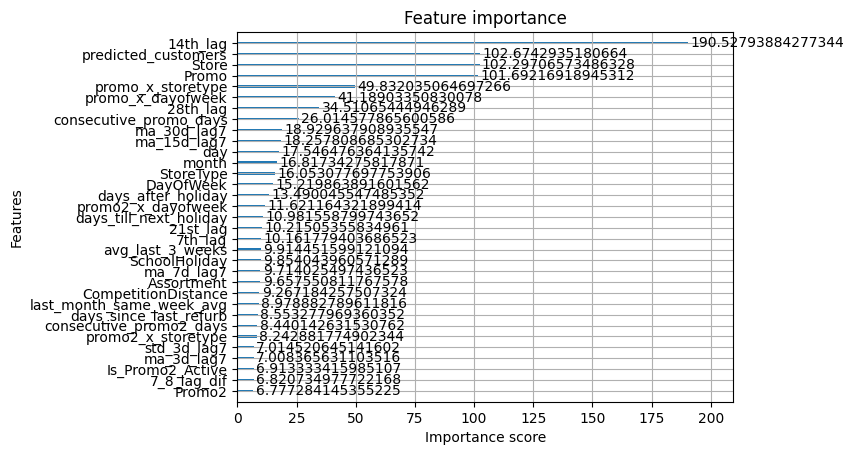

In [ ]:
importance_scores = xgb_early_stopped.get_booster().get_score(importance_type='gain')
from xgboost import plot_importance
# Plot built-in feature importance
plot_importance(xgb_early_stopped, importance_type='gain',)
plt.show()

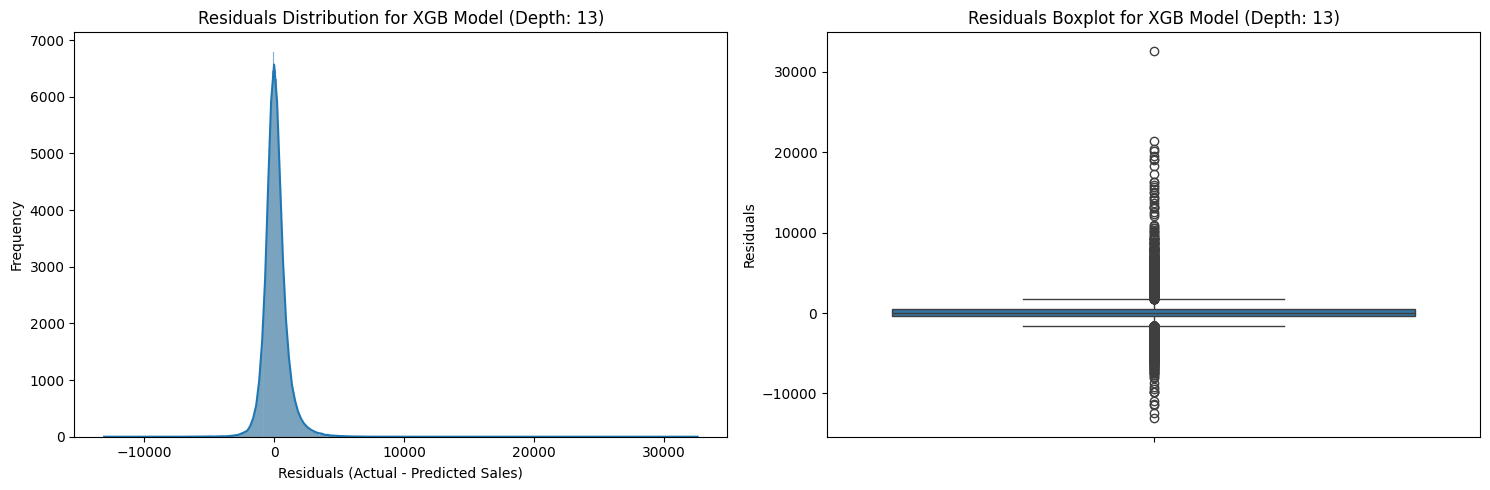

In [ ]:

# Calculate residuals
residuals = y_test_sales - y_pred_early_stopped

# Plot distribution of residuals and boxplot
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Histogram/KDE plot of residuals
sns.histplot(residuals, kde=True, ax=axes[0])
axes[0].set_title(f'Residuals Distribution for XGB Model (Depth: {d})')
axes[0].set_xlabel('Residuals (Actual - Predicted Sales)')
axes[0].set_ylabel('Frequency')

# Boxplot of residuals
sns.boxplot(y=residuals, ax=axes[1])
axes[1].set_title(f'Residuals Boxplot for XGB Model (Depth: {d})')
axes[1].set_ylabel('Residuals')

plt.tight_layout()
plt.show()

In [ ]:
under_pred = residuals > 10000
over_pred = residuals < -10000

under_pred_idx=residuals[under_pred].index
over_pred_idx=residuals[over_pred].index

In [ ]:
variables=['DayOfWeek','Promo','SchoolHoliday','StoreType','Assortment','Is_Promo2_Active','week_of_month','promo_x_dayofweek','promo_x_storetype']

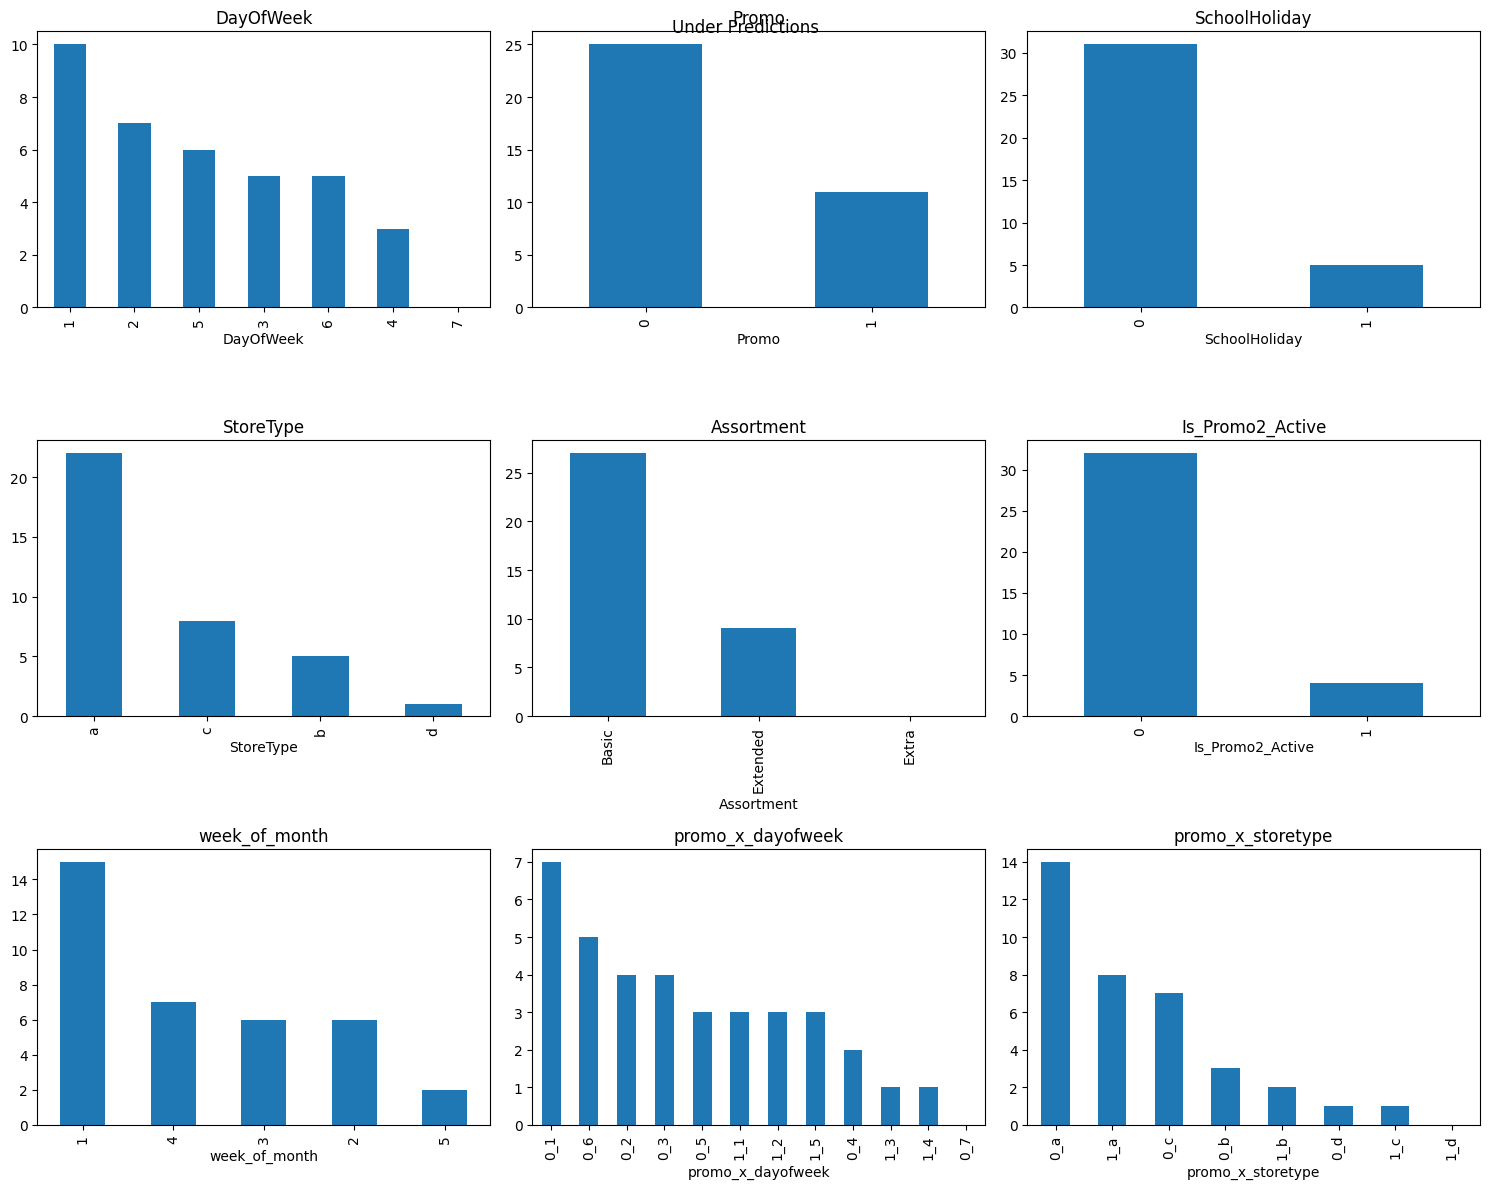

In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()

for i, col in enumerate(variables):
    # Plot directly from df to the specific subplot axis
    df.loc[under_pred_idx][col].value_counts().plot(kind='bar', ax=axes[i])
    axes[i].set_title(col)
    axes[i].tick_params(axis='x')

plt.tight_layout()
plt.suptitle('Under Predictions')
plt.show()    

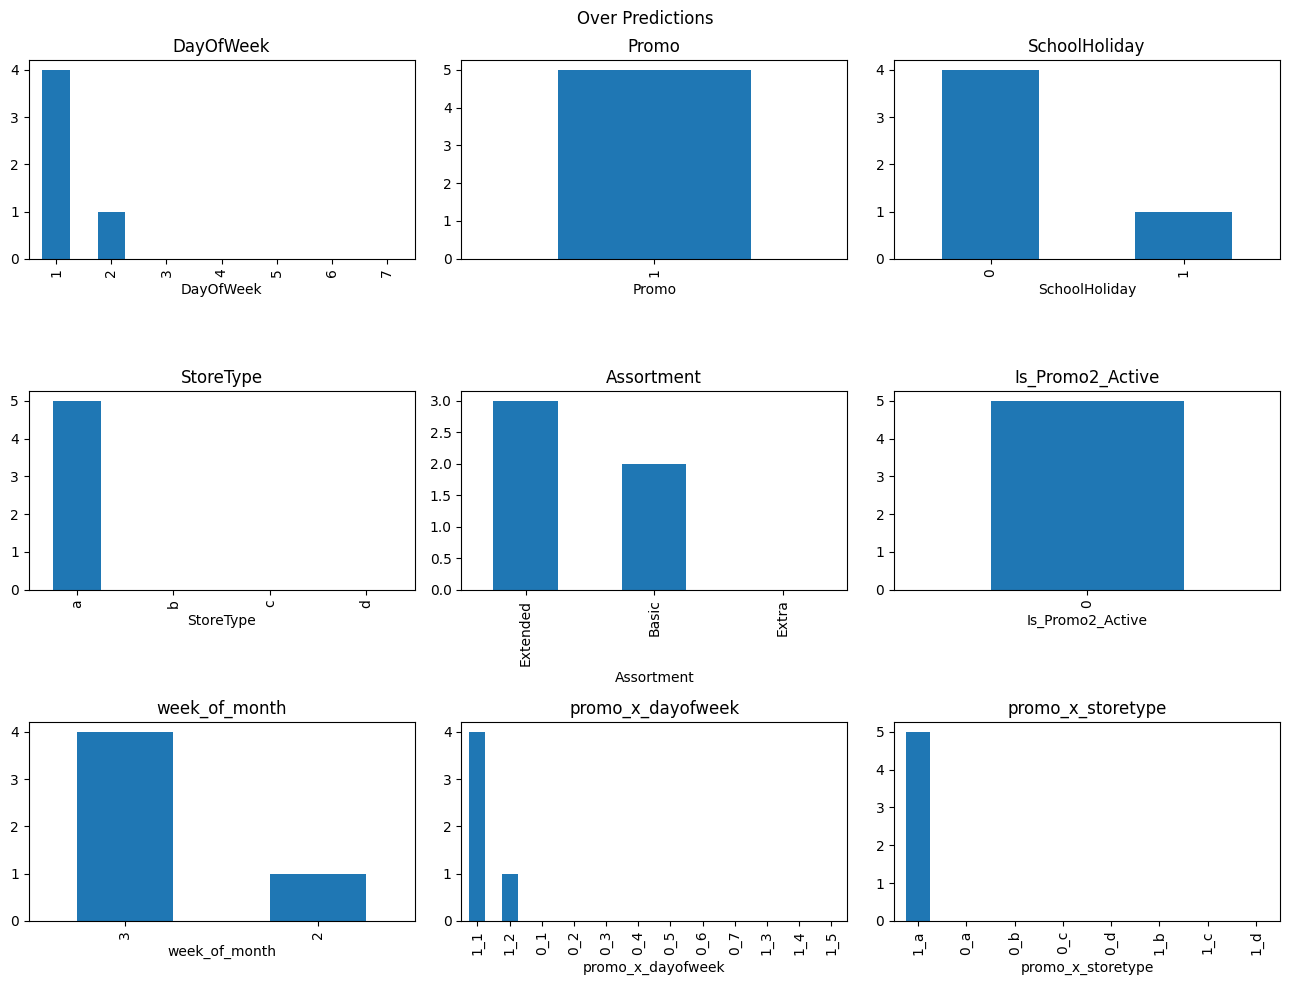

In [ ]:
fig, axes = plt.subplots(3,3, figsize=(13, 10))
axes = axes.flatten()

for i, col in enumerate(variables):
    # Plot directly from df to the specific subplot axis
    df.loc[over_pred_idx][col].value_counts().plot(kind='bar', ax=axes[i])
    axes[i].set_title(col)
    axes[i].tick_params(axis='x')

plt.suptitle('Over Predictions')
plt.tight_layout()
plt.show() 

In [ ]:
sorted_by_keys_desc = dict(sorted(importance_scores.items(), key=lambda item: item[1], reverse=False))
list(sorted_by_keys_desc.keys())[:10]

['days_since_last_refurb',
 'days_until_next_refurb',
 'Is_Promo2_Active',
 'year',
 'consecutive_promo2_days',
 '7_8_lag_dif',
 'Promo2',
 'last_month_same_week_avg',
 'promo2_x_storetype',
 'SchoolHoliday']

In [ ]:
stop

<Figure size 1600x1200 with 0 Axes>

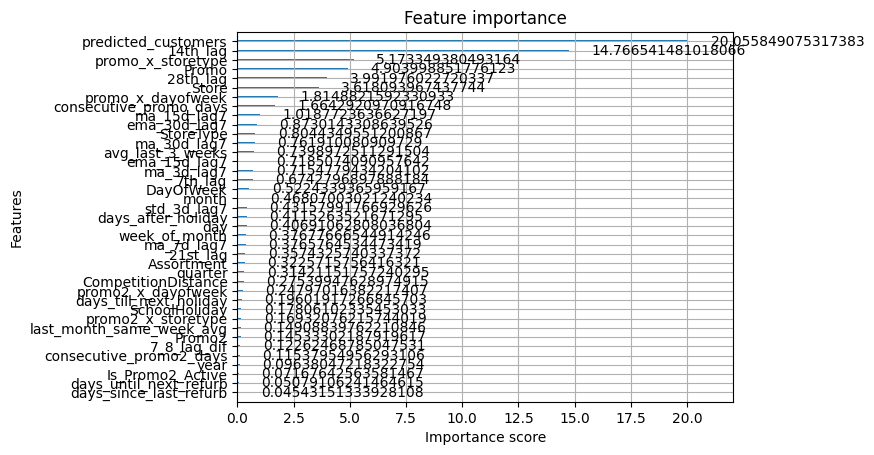

In [ ]:
from xgboost import plot_importance
gain_importance = xgb_early_stopped.feature_importances_

# 3. Extract native Booster metrics
booster = xgb_early_stopped.get_booster()

weight_scores = booster.get_score(importance_type='weight')
gain_scores = booster.get_score(importance_type='gain')
cover_scores = booster.get_score(importance_type='cover')

# 4. Instantly plot built-in metrics
plt.figure(figsize=(16, 12))
plot_importance(xgb_early_stopped, importance_type='gain')
plt.show()

In [ ]:
correlation_with_sales = df.select_dtypes(include=np.number).corr()['Sales'].sort_values(ascending=False)

plt.figure(figsize=(12, 8))
sns.barplot(x=correlation_with_sales.index, y=correlation_with_sales.values, palette='viridis')
plt.title('Correlation of Features with Sales (Before Preprocessing)')
plt.xlabel('Features')
plt.ylabel('Correlation with Sales')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# PCA requires scaled data
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train_augmented_sales)
x_test_scaled = scaler.transform(x_test_augmented_sales)

# Applying PCA
# We'll retain 95% of the variance
pca = PCA(n_components=0.95, random_state=12)
x_train_pca = pca.fit_transform(x_train_scaled)
x_test_pca = pca.transform(x_test_scaled)

print(f"Original feature count: {x_train_augmented_sales.shape[1]}")
print(f"Reduced feature count (PCA): {x_train_pca.shape[1]}")

# Initialize XGBoost with user specified parameters
xgb_pca_model = XGBRegressor(
    n_estimators=3500,
    max_depth=7,
    learning_rate=0.1,
    device='gpu',
    tree_method='auto',
    random_state=12,
    objective='reg:squarederror'
)

# Train model on log-transformed Sales
print("Training XGBoost on PCA-transformed data...")
xgb_pca_model.fit(x_train_pca, np.log1p(y_train_sales))

# Predict and evaluate
y_pred_pca_log = xgb_pca_model.predict(x_test_pca)
y_pred_pca = np.expm1(y_pred_pca_log)

rmse_pca = np.sqrt(mean_squared_error(y_test_sales, y_pred_pca))
mae_pca = mean_absolute_error(y_test_sales, y_pred_pca)
r2_pca = r2_score(y_test_sales, y_pred_pca)

print(f"\nPCA + XGBoost Performance:")
print(f"RMSE: {rmse_pca:.2f}")
print(f"MAE: {mae_pca:.2f}")
print(f"R² Score: {r2_pca:.4f}")

In [ ]:
xgb_early_stopped = XGBRegressor(
    n_estimators=4000,
    max_depth=7,
    learning_rate=0.3,
    device='gpu', # Use GPU if available
    tree_method='auto', # Use appropriate tree method for GPU
    random_state=42,
    early_stopping_rounds=100,
    objective='reg:squarederror'
)

xgb_early_stopped.fit(x_train_augmented_sales, np.log1p(y_train_sales),
                      eval_set=[(x_test_augmented_sales, np.log1p(y_test_sales))],
                      verbose=False)

# Make predictions on the test set and inverse transform them
y_pred_early_stopped_log = xgb_early_stopped.predict(x_test_augmented_sales)
y_pred_early_stopped = np.expm1(y_pred_early_stopped_log)


# # Evaluate the model
rmse_early_stopped = np.sqrt(mean_squared_error(y_test_sales, y_pred_early_stopped))
mae_early_stopped = mean_absolute_error(y_test_sales, y_pred_early_stopped);
r2_early_stopped = r2_score(y_test_sales, y_pred_early_stopped);

print(f'XGBoost Early Stopped Model with depth {d} and n_estimators {xgb_early_stopped.best_iteration}')
print(f'XGBoost Early Stopped Model RMSE: {rmse_early_stopped:.2f}')
print(f'XGBoost Early Stopped Model MAE: {mae_early_stopped:.2f}')
print(f'XGBoost Early Stopped Model R² Score: {r2_early_stopped:.4f}')
print(' ')
print(' ')

# Calculate residuals
residuals = y_test_sales - y_pred_early_stopped

# Plot distribution of residuals and boxplot
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Histogram/KDE plot of residuals
sns.histplot(residuals, kde=True, ax=axes[0])
axes[0].set_title(f'Residuals Distribution for XGB Model (Depth: {d})')
axes[0].set_xlabel('Residuals (Actual - Predicted Sales)')
axes[0].set_ylabel('Frequency')

# Boxplot of residuals
sns.boxplot(y=residuals, ax=axes[1])
axes[1].set_title(f'Residuals Boxplot for XGB Model (Depth: {d})')
axes[1].set_ylabel('Residuals')

plt.tight_layout()
plt.show()

In [ ]:
stop

In [ ]:
Q1 = residuals.quantile(0.25)
Q3 = residuals.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = residuals[(residuals < lower_bound) | (residuals > upper_bound)]

percentage_outliers = (len(outliers) / len(residuals)) * 100

print(f"Number of residuals: {len(residuals)}")
print(f"Number of outliers: {len(outliers)}")
print(f"Percentage of outliers in residuals: {percentage_outliers:.2f}%")

In [ ]:
data_train.shape[0]/df.shape[0]

In [ ]:
print(f"Number of estimators (boosting rounds) used by the early-stopped model: {xgb_early_stopped.best_iteration}")

In [ ]:

# 1. Combine all augmented features and sales targets
x_full_augmented_sales = pd.concat([x_train_augmented_sales, x_test_augmented_sales], axis=0)
y_full_sales = pd.concat([y_train_sales, y_test_sales], axis=0)

number_of_trees = int(1005 * 1.3)

# Ensure column names are strings for XGBoost compatibility
x_full_augmented_sales.columns = x_full_augmented_sales.columns.astype(str)

# 2. Initialize the XGBRegressor with the specified hyperparameters and max_depth=8
xgb_final_model = XGBRegressor(
    n_estimators=number_of_trees,
    max_depth=7,
    learning_rate=0.005,
    device='gpu', # Use GPU if available
    tree_method='auto', # Use appropriate tree method for GPU
    random_state=42,
    objective='reg:squarederror'
)

# 3. Train the model on the full dataset (log-transformed sales)
print("Training XGBoost model on all data with max_depth=8...")
xgb_final_model.fit(x_full_augmented_sales, np.log1p(y_full_sales))

print("Training complete. The final model is named 'xgb_final_model'.")

# Optionally, you can print the number of estimators if early stopping was used, but for training on all data, it's typically full n_estimators unless explicit early stopping is set with a validation set.
# If you had stored the best_iteration from the early stopped model (e.g., xgb_early_stopped.best_iteration) and wanted to use that specific number of estimators here:
# best_n_estimators = 311 # Example from previous runs for a depth (check your output)
# xgb_final_model = XGBRegressor(
#     n_estimators=best_n_estimators, # Use the best number of estimators found during early stopping
#     max_depth=8,
#     learning_rate=0.01,
#     device='gpu',
#     tree_method='auto',
#     random_state=42,
#     objective='reg:squarederror'
# )
# xgb_final_model.fit(x_full_augmented_sales, np.log1p(y_full_sales))

In [ ]:
import numpy as np
from xgboost import XGBRegressor

# 1. Combine all customer features and targets
x_full_customers = pd.concat([x_train, x_test], axis=0)
y_full_customers = pd.concat([y_train_customers, y_test_customers], axis=0)

# Ensure column names are strings for XGBoost compatibility
x_full_customers.columns = x_full_customers.columns.astype(str)

# 2. Initialize the XGBRegressor with the same hyperparameters as xgb_customer_model
xgb_customer_final_model = XGBRegressor(
    n_estimators=int(183*1.3), # From xgb_customer_model in q96MxYhjTaPV
    max_depth=8,      # From xgb_customer_model in q96MxYhjTaPV
    learning_rate=0.03, # From xgb_customer_model in q96MxYhjTaPV
    device='gpu', # Use GPU if available
    random_state=42, # for reproducibility
    objective='reg:squarederror'
)

# 3. Train the model on the full dataset (log-transformed customers)
print("Training XGBoost customer model on all data with specified hyperparameters...")
xgb_customer_final_model.fit(x_full_customers, np.log1p(y_full_customers))

print("Training complete. The final customer model is named 'xgb_customer_final_model'.")

In [ ]:
xgb_early_stopped = XGBRegressor(
    max_depth=8,
    n_estimators=4000,
    learning_rate=0.01,
    device='gpu', # Use GPU if available
    tree_method='auto', # Use appropriate tree method for GPU
    random_state=42,
    objective='reg:squarederror'
)

xgb_early_stopped.fit(x_train_augmented_sales, np.log1p(y_train_sales))

# Make predictions on the test set and inverse transform them
y_pred_early_stopped_log = xgb_early_stopped.predict(x_test_augmented_sales)
y_pred_early_stopped = np.expm1(y_pred_early_stopped_log)

# Evaluate the model
rmse_early_stopped = np.sqrt(mean_squared_error(y_test_sales, y_pred_early_stopped))
mae_early_stopped = mean_absolute_error(y_test_sales, y_pred_early_stopped)
r2_early_stopped = r2_score(y_test_sales, y_pred_early_stopped)

print(f'XGBoost Early Stopped Model RMSE: {rmse_early_stopped:.2f}')
print(f'XGBoost Early Stopped Model MAE: {mae_early_stopped:.2f}')
print(f'XGBoost Early Stopped Model R² Score: {r2_early_stopped:.4f}')

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot residuals distribution
sns.boxplot(y_test_sales - y_pred_early_stopped, ax=axes[0])
axes[0].set_title('Residuals Distribution for Tuned XGB Model')
axes[0].set_xlabel('Residuals (Actual - Predicted Sales)')
axes[0].set_ylabel('Frequency')

# Plot predictions distribution
sns.histplot(y_pred_early_stopped, kde=True, ax=axes[1])
axes[1].set_title('Predictions Distribution for Tuned XGB Model')
axes[1].set_xlabel('Predicted Sales')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

In [ ]:

# Initialize the XGBoost Regressor as the base estimator
xgb = XGBRegressor(
    n_estimators=4000,
    learning_rate=0.2,
    device='gpu', # Use GPU if available
    tree_method='auto', # Use appropriate tree method for GPU
    random_state=42,
    early_stopping_rounds=50,
    objective='reg:squarederror'
)



print("Starting GridSearchCV for XGBoost Sales Model with Predicted Customers...")
# Fit GridSearchCV to the training data using augmented features and sales target
xgb.fit(x_train_augmented_sales, np.log1p(y_train_sales))

print("GridSearchCV completed for Sales Model.")


# Make predictions with the best estimator on the augmented test set
y_pred_tuned_log = xgb.predict(x_test_augmented_sales)
y_pred_tuned = np.expm1(y_pred_tuned_log) # Inverse transform

# Evaluate the best model on the test set using actual sales
rmse_tuned = np.sqrt(mean_squared_error(y_test_sales, y_pred_tuned))
mae_tuned = mean_absolute_error(y_test_sales, y_pred_tuned)
r2_tuned = r2_score(y_test_sales, y_pred_tuned)

print("\n--- Tuned XGBoost Sales Model Performance on Test Set (with Predicted Customers) ---")
print(f'Tuned XGBoost RMSE: {rmse_tuned:.2f}')
print(f'Tuned XGBoost MAE: {mae_tuned:.2f}')
print(f'Tuned XGBoost R² Score: {r2_tuned:.4f}')

# # Plotting cross-validation scores
# cv_results = pd.DataFrame(grid_search_xgb.cv_results_)
# plt.figure(figsize=(15, 7))

# # Plot mean test score against n_estimators, colored by learning_rate and max_depth
# for lr in param_grid['learning_rate']:
#     for md in param_grid['max_depth']:
#         subset = cv_results[(cv_results['param_learning_rate'] == lr) & (cv_results['param_max_depth'] == md)]
#         if not subset.empty:
#             sns.lineplot(x='param_n_estimators', y=-subset['mean_test_score'], data=subset, marker='o', label=f'LR: {lr}, MD: {md}')

# plt.title('Cross-Validated RMSE vs. n_estimators for XGBoost Sales Model (Tuned)')
# plt.xlabel('n_estimators')
# plt.ylabel('Mean RMSE (Cross-Validation)')
# plt.grid(True)
# plt.legend(title='Hyperparameters')
# plt.show()

# # Display the full cross-validation results DataFrame
# result = pd.DataFrame(grid_search_xgb.cv_results_)
# display(result)

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from cuml.ensemble import RandomForestRegressor as cumlRF
from cuml.model_selection import GridSearchCV as cumlGridSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import cudf

# Prepare data for cuML, ensuring float32 dtype for GPU compatibility
# x_train_augmented_sales and y_train_sales are already defined in the notebook context
# Convert to cuDF DataFrames and Series
x_train_gdf_rf = cudf.DataFrame(x_train_augmented_sales.astype('float32'))
y_train_sales_log_gs = cudf.Series(np.log1p(y_train_sales).astype('float32'))

x_test_gdf_rf = cudf.DataFrame(x_test_augmented_sales.astype('float32'))

# Define the parameter grid for GridSearchCV
param_grid_rf = {
    'n_estimators': [500, 700, 1000],
    'max_depth': [10, 15, 20],
    'min_samples_leaf': [1, 5, 10]
}

# Initialize the cuML RandomForestRegressor as the base estimator
rf_estimator = cumlRF(random_state=42, n_streams=0) # n_streams=0 for optimal GPU resource usage

# Initialize GridSearchCV
grid_search_rf = cumlGridSearchCV(
    estimator=rf_estimator,
    param_grid=param_grid_rf,
    cv=3, # Using 3-fold cross-validation
    scoring='neg_mean_squared_error', # cuML GridSearchCV uses neg_mean_squared_error
    # n_jobs is not directly supported in cumlGridSearchCV in the same way as sklearn
    # cuML leverages GPU for parallelization automatically.
    verbose=2
)

print("Starting GridSearchCV for Random Forest Sales Model...")
# Fit GridSearchCV to the training data
grid_search_rf.fit(x_train_gdf_rf, y_train_sales_log_gs)

print("GridSearchCV completed for Random Forest Sales Model.")

# Get the best parameters and best score
best_params_rf = grid_search_rf.best_params_
best_rmse_rf_log = np.sqrt(-grid_search_rf.best_score_) # Convert negative MSE to RMSE

print(f"Best Parameters for Random Forest Sales Model: {best_params_rf}")
print(f"Best Cross-Validated Log1p RMSE for Random Forest Sales Model: {best_rmse_rf_log:.4f}")

# Make predictions with the best estimator on the augmented test set
y_pred_rf_tuned_log = grid_search_rf.best_estimator_.predict(x_test_gdf_rf)
y_pred_rf_tuned = np.expm1(y_pred_rf_tuned_log.to_numpy()) # Inverse transform and convert to numpy

# Evaluate the best model on the test set using actual sales
rmse_rf_tuned = np.sqrt(mean_squared_error(y_test_sales, y_pred_rf_tuned))
mae_rf_tuned = mean_absolute_error(y_test_sales, y_pred_rf_tuned)
r2_rf_tuned = r2_score(y_test_sales, y_pred_rf_tuned)

print("\n--- Tuned Random Forest Sales Model Performance on Test Set (with Predicted Customers) ---")
print(f'Tuned Random Forest RMSE: {rmse_rf_tuned:.2f}')
print(f'Tuned Random Forest MAE: {mae_rf_tuned:.2f}')
print(f'Tuned Random Forest R² Score: {r2_rf_tuned:.4f}')

# Plotting cross-validation results (simplified due to cumlGridSearchCV output structure)
# cuML GridSearchCV doesn't produce a cv_results_ DataFrame like scikit-learn in the same format.
# To visualize, we'd typically need to extract results manually or use custom loops.
# For now, we'll just print the best parameters and scores.


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot residuals distribution
sns.boxplot(y_test - y_pred_tuned, ax=axes[0])
axes[0].set_title('Residuals Distribution for Tuned XGB Model')
axes[0].set_xlabel('Residuals (Actual - Predicted Sales)')
axes[0].set_ylabel('Frequency')

# Plot predictions distribution
sns.histplot(y_pred_tuned, kde=True, ax=axes[1])
axes[1].set_title('Predictions Distribution for Tuned XGB Model')
axes[1].set_xlabel('Predicted Sales')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

In [ ]:
residuals=(y_test - y_pred_tuned)

In [ ]:
Q1 = residuals.quantile(0.25)
Q3 = residuals.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers_indices = residuals[(residuals < lower_bound) | (residuals > upper_bound)].index
outliers = residuals.loc[outliers_indices]

print(f"Number of outliers detected: {len(outliers)}")
print(f"Percentage of outliers: {100 * len(outliers) / len(residuals):.2f}%")

plt.figure(figsize=(10, 6))
sns.boxplot(y=residuals)
plt.title('Residuals Box Plot with Outliers')
plt.ylabel('Residuals')
plt.scatter(x=np.zeros_like(outliers), y=outliers, color='red', s=50, zorder=5, label='Outliers')
plt.legend()
plt.show()

In [ ]:
df.loc[outliers_indices]

In [ ]:
model_performance_summary = {
    'Linear Regression': {'RMSE': 1890.00, 'MAE': 1134.49, 'R2': 0.6514},
    'XGBoost (Default)': {'RMSE': 572.33, 'MAE': 409.27, 'R2': 0.9680},
    'Random Forest (Default)': {'RMSE': 742.86, 'MAE': 521.97, 'R2': 0.9461},
    'Prophet (Standalone)': {'RMSE': rmse_prophet, 'MAE': 'N/A', 'R2': 'N/A'},
    'Prophet + XGBoost Hybrid': {'RMSE': rmse_hybrid, 'MAE': 'N/A', 'R2': 'N/A'},
    'XGBoost (Combined StoreType)': {'RMSE': rmse_comb, 'MAE': mae_comb, 'R2': r2_comb},
    'XGBoost (GridSearchCV Tuned)': {'RMSE': rmse_tuned, 'MAE': mae_tuned, 'R2': r2_tuned}
}

performance_df_summary = pd.DataFrame.from_dict(model_performance_summary, orient='index')
performance_df_summary.index.name = 'Model'

# Sort by RMSE for better comparison, handling 'N/A' values if any
performance_df_summary['RMSE_sort'] = pd.to_numeric(performance_df_summary['RMSE'], errors='coerce')
performance_df_summary = performance_df_summary.sort_values(by='RMSE_sort', ascending=True).drop(columns='RMSE_sort')

print("\n--- Overall Model Performance Comparison ---")
display(performance_df_summary.round(4))


In [ ]:
prophet_df.shape[0]*0.5

In [ ]:
prophet_train=prophet_df.iloc[:-74]
prophet_test=prophet_df.iloc[-74:]

m = Prophet()
m.fit(prophet_train)
future = m.make_future_dataframe(periods=74, freq='D')
forecast = m.predict(future)
forecast.tail()

In [ ]:
predictions = forecast.iloc[-74:]['yhat']

# Calculate RMSE
rmse_prophet = np.sqrt(mean_squared_error(prophet_test['y'], predictions))
print(f"Prophet Test RMSE: {rmse_prophet:.2f}")

# Plotting
plt.figure(figsize=(15, 6))
plt.plot(prophet_train['ds'], prophet_train['y'], label='Train Set', color='blue')
plt.plot(prophet_test['ds'], prophet_test['y'], label='Test Set (Actual)', color='green')
plt.plot(prophet_test['ds'], predictions, label='Predictions', color='red', linestyle='--')

plt.title('Prophet Model: Train vs Test vs Predictions')
plt.xlabel('Date')
plt.ylabel('Sales')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from prophet import Prophet
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error

# 1. Prepare prophet_df and features
# Ensure prophet_df has 'ds' as a column
# if 'ds' not in prophet_df.columns:
#     prophet_df = prophet_df.reset_index().rename(columns={'Date': 'ds'})

# Reload the original indexed dataframe for features if needed
df_raw = pd.read_parquet('final_data.parquet')

# Aggregate daily features (Promo, etc.)
daily_features = df_raw.groupby(df_raw.index)[['Promo', 'SchoolHoliday', 'Promo2']].mean().reset_index()
daily_features.rename(columns={'Date': 'ds'}, inplace=True)

# Ensure both are datetime for the merge
prophet_df['ds'] = pd.to_datetime(prophet_df['ds'])
daily_features['ds'] = pd.to_datetime(daily_features['ds'])

# Merge additional features into prophet_df
prophet_df_extended = prophet_df.merge(daily_features, on='ds', how='left')

# 2. Split data
n = len(prophet_df_extended)
train_50_idx = int(n * 0.5)
train_75_idx = int(n * 0.75)

df_50 = prophet_df_extended.iloc[:train_50_idx]
df_next_25 = prophet_df_extended.iloc[train_50_idx:train_75_idx]
df_test_25 = prophet_df_extended.iloc[train_75_idx:]

# 3. Train first Prophet on 50% and calculate residuals on next 25%
m1 = Prophet()
m1.fit(df_50[['ds', 'y']])

forecast_25 = m1.predict(df_next_25[['ds']])
residuals_25 = df_next_25['y'].values - forecast_25['yhat'].values

# 4. Train XGBoost on these residuals
def extract_features(data_in):
    temp = data_in.copy()
    temp['month'] = temp['ds'].dt.month
    temp['day'] = temp['ds'].dt.day
    temp['dayofweek'] = temp['ds'].dt.dayofweek
    return temp[['month', 'day', 'dayofweek', 'Promo', 'SchoolHoliday', 'Promo2']]

X_train_xgb = extract_features(df_next_25)
y_train_xgb = residuals_25

xgb_res_model = XGBRegressor(n_estimators=200, learning_rate=0.03, max_depth=6, device='gpu')
xgb_res_model.fit(X_train_xgb, y_train_xgb)

# 5. Final pass: Train Prophet on 75% and predict last 25%
df_75 = prophet_df_extended.iloc[:train_75_idx]
m2 = Prophet()
m2.fit(df_75[['ds', 'y']])

forecast_final = m2.predict(df_test_25[['ds']])
X_test_xgb = extract_features(df_test_25)
residual_correction = xgb_res_model.predict(X_test_xgb)

# Combine Prophet + XGBoost correction
final_predictions = forecast_final['yhat'].values + residual_correction

# Evaluation
rmse_hybrid = np.sqrt(mean_squared_error(df_test_25['y'], final_predictions))
print(f"Hybrid RMSE: {rmse_hybrid:.2f}")

# Plot
plt.figure(figsize=(15, 7))
plt.plot(df_75['ds'], df_75['y'], label='Train (75%)', color='blue')
plt.plot(df_test_25['ds'], df_test_25['y'], label='Test Actual', color='green')
plt.plot(df_test_25['ds'], final_predictions, label='Hybrid Forecast', color='red', linestyle='--')
plt.title('Prophet + XGBoost Hybrid Forecasting')
plt.legend()
plt.show()

In [ ]:
# Features to drop from subsets to avoid data leakage or constant features
features_to_drop_for_submodels = ['StoreType_a', 'StoreType_b', 'StoreType_c', 'StoreType_d']

# --- Prepare training data for StoreType 'b' ---
mask_b_train = x_train['StoreType_b'] == 1
x_train_b_sub = x_train[mask_b_train].drop(columns=features_to_drop_for_submodels)
y_train_b_sub = y_train[mask_b_train]

# --- Prepare training data for other StoreTypes ---
x_train_other_sub = x_train[~mask_b_train].drop(columns=features_to_drop_for_submodels)
y_train_other_sub = y_train[~mask_b_train]

# --- Train Models ---
print("Training XGBoost model for StoreType 'b' using x_train subset...")
xgb_model_b = XGBRegressor(device='gpu', random_state=42)
xgb_model_b.fit(x_train_b_sub, np.log1p(y_train_b_sub))

print("Training XGBoost model for other StoreTypes using x_train subset...")
xgb_model_other = XGBRegressor(device='gpu', random_state=42)
xgb_model_other.fit(x_train_other_sub, np.log1p(y_train_other_sub))

# --- Combined Prediction Function ---
def predict_combined(X_input_df, model_b, model_other, drop_cols):
    y_pred = pd.Series(index=X_input_df.index, dtype=float)
    mask_b = X_input_df['StoreType_b'] == 1

    # Store B predictions
    if mask_b.any():
        X_b_proc = X_input_df[mask_b].drop(columns=drop_cols, errors='ignore')
        y_pred[mask_b] = np.expm1(model_b.predict(X_b_proc))

    # Other Store predictions
    if (~mask_b).any():
        X_other_proc = X_input_df[~mask_b].drop(columns=drop_cols, errors='ignore')
        y_pred[~mask_b] = np.expm1(model_other.predict(X_other_proc))

    return y_pred

# --- Evaluate on x_test, y_test ---
print("\n--- Evaluating Combined Model on x_test ---")
combined_test_preds = predict_combined(x_test, xgb_model_b, xgb_model_other, features_to_drop_for_submodels)

rmse_comb = np.sqrt(mean_squared_error(y_test, combined_test_preds))
mae_comb = mean_absolute_error(y_test, combined_test_preds)
r2_comb = r2_score(y_test, combined_test_preds)

print(f'Combined Model RMSE: {rmse_comb:.2f}')
print(f'Combined Model MAE: {mae_comb:.2f}')
print(f'Combined Model R² Score: {r2_comb:.4f}')

In [ ]:
stop

In [ ]:
# df_2=df.copy()
# for i in [0.99,0.95]:

#     df_2['Sales'] = df['Sales'].clip(upper=df['Sales'].quantile(i))
#     df_2['Customers'] = df['Customers'].clip(upper=df['Customers'].quantile(i))

#     x_train, x_test, y_train, y_test = train_test_split(df_2.drop(columns=['Sales']), df_2['Sales'], test_size=0.2, random_state=42)

#     print(' ')
#     print(f'Clipping Quantile : {i}')
#     print(' ')
#     for model_name, model in models.items():
#         rmse_score = test_model(model,model_name)


In [ ]:
# encoded_df = df.reset_index(drop=True).copy()
# encoded_months = encoded_months.reset_index(drop=True)
# encoded_df = pd.concat([encoded_df, encoded_Data, encoded_months], axis=1)

# categorical_features_to_drop = ['DayOfWeek', 'year', 'month', 'StoreType', 'Assortment', 'PromoInterval']
# encoded_df = encoded_df.drop(columns=categorical_features_to_drop)

# encoded_df.head()

In [ ]:
# categorical_features = ['DayOfWeek', 'year', 'month', 'day','StoreType', 'Assortment']
# encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
# encoded_data_array = encoder.fit_transform(df[categorical_features])
# encoded_Data = pd.DataFrame(encoded_data_array, columns=encoder.get_feature_names_out(categorical_features))
# encoded_Data.head()

In [ ]:
# encoded_months = df['PromoInterval'].str.replace(' ', '').str.get_dummies(sep=',')
# encoded_months.columns = [f"Promo_{col}" for col in encoded_months.columns]
# encoded_months.head()

In [ ]:
xgb_model_default = XGBRegressor(
    device='gpu', # Use GPU if available for faster training
    random_state=42 # for reproducibility
)

# Train the model on the log-transformed target variable
xgb_model_default.fit(x_train, np.log1p(y_train))

# Make predictions on the test set and inverse transform them
y_pred_xgb_default_log = xgb_model_default.predict(x_test)
y_pred_xgb_default = np.expm1(y_pred_xgb_default_log)

# Evaluate the model
rmse_xgb_default = np.sqrt(mean_squared_error(y_test, y_pred_xgb_default))
mae_xgb_default = mean_absolute_error(y_test, y_pred_xgb_default)
r2_xgb_default = r2_score(y_test, y_pred_xgb_default)

print(f'XGBoost Default RMSE: {rmse_xgb_default:.2f}')
print(f'XGBoost Default MAE: {mae_xgb_default:.2f}')
print(f'XGBoost Default R² Score: {r2_xgb_default:.4f}')

# Plotting residuals
plt.figure(figsize=(10, 5))
xgb_def_residuals = y_test - y_pred_xgb_default
sns.histplot(xgb_def_residuals, kde=True)
plt.title('Residuals Distribution for XGBoost Default Model')
plt.xlabel('Residuals (Actual - Predicted Sales)')
plt.ylabel('Frequency')
plt.show()

In [ ]:

`# from sklearn.ensemble import RandomForestRegressor

# # Initialize Random Forest Regressor with default hyperparameters
# rf_model_default = RandomForestRegressor(random_state=42, n_jobs=-1) # n_jobs=-1 to use all available cores

# # Train the model on the log-transformed target variable
# rf_model_default.fit(x_train, np.log1p(y_train))

# # Make predictions on the test set and inverse transform them
# y_pred_rf_default = np.expm1(rf_model_default.predict(x_test))

# # Evaluate the model
# rmse_rf_default = np.sqrt(mean_squared_error(y_test, y_pred_rf_default))
# mae_rf_default = mean_absolute_error(y_test, y_pred_rf_default)
# r2_rf_default = r2_score(y_test, y_pred_rf_default)

# print(f'Random Forest Default RMSE: {rmse_rf_default:.2f}')
# print(f'Random Forest Default MAE: {mae_rf_default:.2f}')
# print(f'Random Forest Default R² Score: {r2_rf_default:.4f}')

# # Plotting residuals
# plt.figure(figsize=(10, 5))
# sns.histplot(y_test - y_pred_rf_default, kde=True)
# plt.title('Residuals Distribution for Random Forest Default Model')
# plt.xlabel('Residuals (Actual - Predicted Sales)')
# plt.ylabel('Frequency')
# plt.show()

In [ ]:
fig, ax = plt.subplots(1,2,figsize=(10, 6))
sns.histplot(y_train, bins=50, kde=True,ax=ax[0])
ax[0].set_title('Distribution of Sales (Train)')
sns.histplot(np.log1p(y_train), bins=50, kde=True, ax=ax[1])
ax[1].set_title('Distribution of Log(Sales) (Train)')

In [ ]:
from sklearn.model_selection import cross_val_score

# Initialize XGBoost Regressor
xgb_model_cv = XGBRegressor(
    n_estimators=100,  # Default n_estimators
    learning_rate=0.1, # Default learning_rate
    max_depth=5,       # Default max_depth
    random_state=42,
    device='gpu',      # Use GPU if available
    tree_method='auto'

)

# Perform cross-validation
# The scoring 'neg_root_mean_squared_error' is used as cross_val_score maximizes the score,
# so we take the negative RMSE to find the minimum RMSE.
cv_scores = cross_val_score(xgb_model_cv, x_train, np.log1p(y_train),
                            cv=5, scoring='neg_root_mean_squared_error', n_jobs=-1)

# Convert negative RMSE to positive RMSE
rmse_scores = -cv_scores

print(f'XGBoost Cross-Validation RMSE scores: {rmse_scores}')
print(f'Mean RMSE: {rmse_scores.mean():.2f}')
print(f'Standard Deviation of RMSE: {rmse_scores.std():.2f}')

In [ ]:
stop

In [ ]:

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outliers_over = xgb_def_residuals[xgb_def_residuals > upper_bound]
outliers_under = xgb_def_residuals[xgb_def_residuals < lower_bound]

print(f"Number of over-outliers: {len(outliers_over)}")
print(f"Number of under-outliers: {len(outliers_under)}")
# print(f'percentage of outlier from Total prediction : {100*(len(outliers)/len(y_test)):.2f}')


In [ ]:
# Combine x_test and residuals into a single DataFrame
x_test_with_residuals = x_test.copy()
x_test_with_residuals['Residuals'] = xgb_def_residuals

# Calculate the correlation of test features with residuals
correlation_with_residuals = x_test_with_residuals.corr()['Residuals'].drop('Residuals').sort_values(ascending=False)

# Plotting the correlation
plt.figure(figsize=(12, 6))
sns.barplot(x=correlation_with_residuals.index, y=correlation_with_residuals.values, palette='viridis')
plt.xticks(rotation=90)
plt.title('Correlation of Test Features with XGBoost Residuals')
plt.xlabel('Features')
plt.ylabel('Correlation with Residuals')
plt.tight_layout()
plt.show()

In [ ]:
stop

In [ ]:
GS_params = {
    'learning_rate': [ 0.1,0.3,0.5,0.7],

}

GS_model=XGBRegressor(device='gpu', tree_method='auto',n_estimators=700,learning_rate=0.3, max_depth=6, random_state=42)

grid_search = GridSearchCV(estimator=GS_model, param_grid=GS_params, cv=3, n_jobs=-1, scoring='neg_root_mean_squared_error')
grid_search.fit(X_train, np.log1p(y_train))

# result=pd.DataFrame(grid_search.cv_results_)
# sns.lineplot(x='param_learning_rate', y='mean_test_score', data=result)
#result[['mean_test_score','param_max_depth','param_n_estimators']].sort_values('mean_test_score', ascending=False).head()

In [ ]:
y_pred=np.expm1(grid_search.predict(X_test))
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)
sns.histplot(y_test - y_pred, kde=True)
r2 = r2_score(y_test, y_pred)
print(f'RMSE: {rmse:.2f}')
print(f'MAE: {mae:.2f}')
print(f'R² Score: {r2:.4f}')


In [ ]:
X_test.shape

In [ ]:
loda

In [ ]:
import cudf
import numpy as np
from cuml.ensemble import RandomForestRegressor as cumlRF
from cuml.model_selection import GridSearchCV as cumlGridSearchCV
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error

# Prepare data for GPU: XGBoost handles pandas but cuML performs better with float32
X_train_f32 = X_train.astype('float32')
X_test_f32 = X_test.astype('float32')
y_train_log = np.log1p(y_train).astype('float32')

# Convert to cuDF for cuML consistency
X_train_gdf = cudf.DataFrame(X_train_f32)
y_train_gs = cudf.Series(y_train_log)

# 1. XGBoost Regressor with specified GPU hyperparameters
xgb_model = XGBRegressor(
    device='gpu',
    tree_method='auto',
    n_estimators=900,
    learning_rate=0.3,
    max_depth=7,
    random_state=42
)

xgb_model.fit(X_train, np.log1p(y_train))

# 2. cuML Random Forest Regressor with Hyperparameter Tuning
rf_gpu = cumlRF(random_state=42)

rf_params = {
    'n_estimators': [100, 300, 500],
    'max_depth': [10, 15],

}

rf_grid = cumlGridSearchCV(
    estimator=rf_gpu,
    param_grid=rf_params,
    cv=3,
    scoring='neg_mean_squared_error'
)

rf_grid.fit(X_train_gdf, y_train_gs)

# Predictions and Evaluation
y_pred_xgb = np.expm1(xgb_model.predict(X_test))

# Best cuML RF Model
best_rf = rf_grid.best_estimator_
y_pred_rf = np.expm1(best_rf.predict(X_test_f32).to_pandas())

rmse_xgb = np.sqrt(mean_squared_error(y_test, y_pred_xgb))
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))

print(f"XGBoost (GPU) RMSE: {rmse_xgb:.4f}")
print(f"cuML Random Forest (Tuned) RMSE: {rmse_rf:.4f}")
print(f"Best RF Parameters: {rf_grid.best_params_}")